In [1]:
# Cell 1 — imports
from pathlib import Path

import numpy as np
from PIL import Image
from scipy import ndimage
import geopandas as gpd
import pandas as pd
from shapely.geometry import Point
import matplotlib.pyplot as plt

DATA_RAW = Path("../data/raw/kandy")
DATA_PROCESSED = Path("../data/processed")
DATA_RAW.mkdir(parents=True, exist_ok=True)


In [2]:
import fitz
from pathlib import Path

def pdf_to_png(pdf_path, out_prefix, dpi=300):
    pdf_path = Path(pdf_path)

    if not pdf_path.exists():
        raise FileNotFoundError(f"PDF not found: {pdf_path}")

    doc = fitz.open(pdf_path)

    page = doc[0]

    zoom = dpi / 72
    matrix = fitz.Matrix(zoom, zoom)

    pix = page.get_pixmap(matrix=matrix, alpha=False)

    png_path = Path(f"{out_prefix}-1.png")
    pix.save(str(png_path))

    doc.close()

    return png_path

In [3]:

MAP_NAME = "kandy"  


In [4]:
pdf_path = DATA_RAW / f"{MAP_NAME.upper()}.pdf"

png_path = pdf_to_png(
    pdf_path,
    str(DATA_RAW / MAP_NAME)
)

im = Image.open(png_path).convert("RGB")
arr = np.array(im)

In [5]:
def find_frame_borders(arr, search_margin=300):
    h, w, _ = arr.shape

    # left border
    region = arr[h//4:3*h//4, 100:400, :]
    gray = region.sum(axis=2)
    frac_dark = (gray < 300).mean(axis=0)
    left = np.where(frac_dark > 0.5)[0][0] + 100

    # right border — search from ~65% width onward, before any legend column
    region = arr[h//4:3*h//4, int(w*0.6):int(w*0.75), :]
    gray = region.sum(axis=2)
    frac_dark = (gray < 300).mean(axis=0)
    right = np.where(frac_dark > 0.5)[0][0] + int(w*0.6)

    # top border
    region = arr[100:500, left:right, :]
    gray = region.sum(axis=2)
    frac_dark = (gray < 300).mean(axis=1)
    top = np.where(frac_dark > 0.5)[0][0] + 100

    # bottom border
    region = arr[int(h*0.6):int(h*0.85), left:right, :]
    gray = region.sum(axis=2)
    frac_dark = (gray < 300).mean(axis=1)
    bottom = np.where(frac_dark > 0.5)[0][0] + int(h*0.6)

    return left, right, top, bottom

X_MIN, X_MAX, Y_MIN, Y_MAX = find_frame_borders(arr)
print(f"Frame: x=[{X_MIN},{X_MAX}], y=[{Y_MIN},{Y_MAX}]")


Frame: x=[170,2978], y=[100,2758]


In [6]:
def zoom_crop(arr, x0, y0, x1, y1, scale=3, save_path="zoom_check.png"):
    crop = Image.fromarray(arr[y0:y1, x0:x1])
    crop = crop.resize((crop.width*scale, crop.height*scale), Image.LANCZOS)
    crop.save(save_path)
    return save_path

# Adjust these coordinates to scan near where you expect gridline labels —
# start wide, narrow down once you see a label, same process used for Kandy.
zoom_crop(arr, 1700, 150, 1950, 300, save_path="zoom_lon_a.png")
# view zoom_lon_a.png, note which longitude label it shows and its exact pixel x — repeat for a 2nd longitude and 2 latitudes


'zoom_lon_a.png'

In [7]:
def find_vertical_gridline(arr, x_search_start, x_search_end, y0, y1):
    """Find the exact x pixel of a vertical gridline within a narrow search window."""
    strip = arr[y0:y1, x_search_start:x_search_end, :]
    gray = strip.sum(axis=2)
    frac_dark = (gray < 400).mean(axis=0)
    candidates = np.where(frac_dark > 0.5)[0]
    return int(np.mean(candidates)) + x_search_start if len(candidates) else None

def find_horizontal_gridline(arr, y_search_start, y_search_end, x0, x1):
    """Find the exact y pixel of a horizontal gridline within a narrow search window."""
    strip = arr[y_search_start:y_search_end, x0:x1, :]
    gray = strip.sum(axis=2)
    frac_dark = (gray < 400).mean(axis=1)
    candidates = np.where(frac_dark > 0.5)[0]
    return int(np.mean(candidates)) + y_search_start if len(candidates) else None


In [8]:
# ----- CHANGE PER MAP: fill these in after visually confirming with Cell 4/5 -----
CALIBRATION = {
    "lon_a_deg": 80.75, "lon_a_px": 1824,   # e.g. "80°45'E" confirmed at x=1824
    "lon_b_deg": 81.00, "lon_b_px": 2979,   # e.g. "81°00'E" confirmed at x=2979
    "lat_a_deg": 7.50,  "lat_a_px": 432,    # e.g. "7°30'N" confirmed at y=432
    "lat_b_deg": 7.25,  "lat_b_px": 1596,   # e.g. "7°15'N" confirmed at y=1596
}
# -----------------------------------------------------------------------------

px_per_deg_lon = (CALIBRATION["lon_b_px"] - CALIBRATION["lon_a_px"]) / (CALIBRATION["lon_b_deg"] - CALIBRATION["lon_a_deg"])
px_per_deg_lat = (CALIBRATION["lat_b_px"] - CALIBRATION["lat_a_px"]) / (CALIBRATION["lat_b_deg"] - CALIBRATION["lat_a_deg"])

def px_to_lonlat(x_full, y_full):
    lon = CALIBRATION["lon_a_deg"] + (x_full - CALIBRATION["lon_a_px"]) / px_per_deg_lon
    lat = CALIBRATION["lat_a_deg"] + (y_full - CALIBRATION["lat_a_px"]) / px_per_deg_lat
    return lon, lat

# sanity check: convert the frame corners, confirm they're roughly sensible for the district
print("Top-left corner:", px_to_lonlat(X_MIN, Y_MIN))
print("Bottom-right corner:", px_to_lonlat(X_MAX, Y_MAX))


Top-left corner: (80.39199134199134, 7.571305841924398)
Bottom-right corner: (80.99978354978354, 7.000429553264604)


In [9]:
def sample_dot_color(arr, x0, y0, x1, y1):
    region = arr[y0:y1, x0:x1]
    r, g, b = region[:,:,0].astype(int), region[:,:,1].astype(int), region[:,:,2].astype(int)
    is_red = (r > 150) & (g < 80) & (b < 80)
    ys, xs = np.where(is_red)
    if len(ys) == 0:
        raise ValueError("No red pixels found in legend crop — adjust the region")
    samples = region[ys, xs]
    print(f"{len(ys)} red pixels found, sample colors:", samples[:5])
    return samples, len(ys)

# Optional: sanity-check the legend "Landslides" dot colour looks like the
# map's dots. NOT used for calibration anymore -- detect_dots auto-calibrates
# single_dot_area from the median area of real dots on the map itself, which
# is more reliable than a single legend swatch.
zoom_crop(arr, 3300, 450, 3900, 650, save_path="zoom_legend_check.png")
_, legend_dot_area = sample_dot_color(arr, 3340, 590, 3400, 640)
print("Legend dot area (px, reference only):", legend_dot_area)


179 red pixels found, sample colors: [[167   0   7]
 [191   0  13]
 [202   2  21]
 [207   2  22]
 [207   0  15]]
Legend dot area (px, reference only): 179


In [10]:
# Landslide dot detection — handles fused/overlapping clusters of dots.
#
# Roads/text vs. dot clusters are told apart with an EROSION test instead
# of aspect-ratio/solidity: shrink each red blob by a couple of pixels.
#   - A thin road or text stroke disappears completely under erosion.
#   - A cluster of overlapping dots still has a solid core left over,
#     no matter how large or irregularly shaped the cluster is.
# This lets large fused clusters through (which the old aspect/solidity/
# max-size filters were wrongly rejecting), while still discarding roads.
#
# Splitting still uses the two-pass median-area calibration: the number of
# points inside a blob = round(area / single_dot_area), found as separated
# peaks of a smoothed distance transform, capped at that expected count.

import numpy as np
from scipy import ndimage
from skimage.feature import peak_local_max
from skimage.measure import regionprops
from skimage.morphology import disk, binary_opening, binary_erosion


def _find_valid_blobs(
    arr, x_min, x_max, y_min, y_max,
    r_min, g_max, b_max, red_diff,
    min_area, erosion_radius, min_fill
):
    body = arr[y_min:y_max, x_min:x_max]
    r = body[:, :, 0].astype(np.int16)
    g = body[:, :, 1].astype(np.int16)
    b = body[:, :, 2].astype(np.int16)

    red_mask = (
        (r >= r_min) & (g <= g_max) & (b <= b_max) &
        ((r - g) >= red_diff) & ((r - b) >= red_diff)
    )
    red_clean = binary_opening(red_mask, footprint=disk(1))
    labeled, n = ndimage.label(red_clean, structure=np.ones((3, 3)))

    valid_regions = []
    for region in regionprops(labeled):
        area = region.area
        if area < min_area:
            continue

        minr, minc, maxr, maxc = region.bbox
        h, w = maxr - minr, maxc - minc
        fill_ratio = area / (w * h) if w and h else 0
        if fill_ratio < min_fill:
            continue  # too sparse to be a solid dot/cluster

        # Erosion test: thin roads/text vanish, round dot clusters survive.
        local = labeled[minr:maxr, minc:maxc] == region.label
        eroded = binary_erosion(local, footprint=disk(erosion_radius))
        if eroded.sum() == 0:
            continue  # thin line -> reject

        valid_regions.append(region)

    return red_mask, labeled, valid_regions


def detect_dots(
    arr,
    x_min, x_max, y_min, y_max,

    # Red colour
    r_min=150, g_max=100, b_max=100, red_diff=70,

    # Shape filters -- now just area floor + fill ratio + erosion survival
    min_area=35,
    min_fill=0.45,
    erosion_radius=2,

    # Splitting behaviour
    single_dot_area=None,   # None -> auto-calibrate from median blob area on this map
    split_threshold=1.4,    # a blob must be at least this many x single_dot_area before splitting
    min_distance=7,
    smooth_sigma=1.5
):
    red_mask, labeled, valid_regions = _find_valid_blobs(
        arr, x_min, x_max, y_min, y_max,
        r_min, g_max, b_max, red_diff,
        min_area, erosion_radius, min_fill
    )

    areas = np.array([reg.area for reg in valid_regions])

    if single_dot_area is None:
        # Median is robust to the occasional huge fused cluster skewing it,
        # since most blobs on the map are still isolated single dots.
        single_dot_area = float(np.median(areas))
        print(f"Auto-calibrated single_dot_area = {single_dot_area:.1f} px "
              f"(from {len(areas)} candidate blobs)")

    marker_mask = np.zeros(labeled.shape, dtype=bool)
    points_px = []

    for region in valid_regions:
        minr, minc, maxr, maxc = region.bbox
        area = region.area
        marker_mask[labeled == region.label] = True

        pad = 3
        r0 = max(minr - pad, 0)
        c0 = max(minc - pad, 0)
        r1 = min(maxr + pad, labeled.shape[0])
        c1 = min(maxc + pad, labeled.shape[1])

        local_mask = labeled[r0:r1, c0:c1] == region.label
        local_dist = ndimage.distance_transform_edt(local_mask)
        if smooth_sigma > 0:
            local_dist = ndimage.gaussian_filter(local_dist, sigma=smooth_sigma)

        if area < single_dot_area * split_threshold:
            expected_n = 1
        else:
            expected_n = max(1, round(area / single_dot_area))

        if expected_n == 1:
            cy, cx = np.unravel_index(np.argmax(local_dist), local_dist.shape)
            points_px.append((cx + c0 + x_min, cy + r0 + y_min))
        else:
            coords = peak_local_max(
                local_dist,
                min_distance=min_distance,
                labels=local_mask,
                num_peaks=expected_n,
                exclude_border=False
            )
            if len(coords) == 0:
                cy, cx = region.centroid
                points_px.append((cx + x_min, cy + y_min))
            else:
                for cy, cx in coords:
                    points_px.append((cx + c0 + x_min, cy + r0 + y_min))

    return points_px, red_mask, marker_mask, single_dot_area


In [11]:
import numpy as np


def remove_duplicate_points(points_px, duplicate_radius=10):
    """
    Safety-net merge for any detections that still end up implausibly close
    together (e.g. two adjacent blobs each independently centring on the
    same seam). Nearby points are averaged into one.
    """
    if not points_px:
        return []

    points = np.array(points_px, dtype=float)
    used = np.zeros(len(points), dtype=bool)
    kept = []

    for i in range(len(points)):
        if used[i]:
            continue
        cluster = [points[i]]
        used[i] = True
        for j in range(i + 1, len(points)):
            if used[j]:
                continue
            if np.linalg.norm(points[i] - points[j]) < duplicate_radius:
                cluster.append(points[j])
                used[j] = True
        cluster = np.array(cluster)
        kept.append(tuple(cluster.mean(axis=0)))

    return kept


In [12]:
points_raw, red_mask, marker_mask, SINGLE_DOT_AREA = detect_dots(
    arr,
    X_MIN, X_MAX, Y_MIN, Y_MAX,
    single_dot_area=None,   # auto-calibrate from the map's own dots
    split_threshold=1.6,
    min_distance=8,
    smooth_sigma=1.5
)

print("Raw detected:", len(points_raw))

points_px = remove_duplicate_points(points_raw, duplicate_radius=10)

print("After duplicate removal:", len(points_px))


C:\Users\PCC\AppData\Local\Temp\ipykernel_15784\3720505156.py:36: FutureWarning: `binary_opening` is deprecated since version 0.26 and will be removed in version 0.28. Use `skimage.morphology.opening` instead.
  red_clean = binary_opening(red_mask, footprint=disk(1))
C:\Users\PCC\AppData\Local\Temp\ipykernel_15784\3720505156.py:53: FutureWarning: `binary_erosion` is deprecated since version 0.26 and will be removed in version 0.28. Use `skimage.morphology.erosion` instead. Note the pixel shift by 1 for even-sized footprints (see docstring notes).
  eroded = binary_erosion(local, footprint=disk(erosion_radius))


Auto-calibrated single_dot_area = 322.0 px (from 292 candidate blobs)
Raw detected: 292
After duplicate removal: 291


In [13]:
def build_geodataframe(points_px, px_to_lonlat_fn, district_name, source_label):
    records = []
    for x, y in points_px:
        lon, lat = px_to_lonlat_fn(x, y)
        records.append({"longitude": lon, "latitude": lat})
    df = pd.DataFrame(records)
    gdf = gpd.GeoDataFrame(df, geometry=gpd.points_from_xy(df.longitude, df.latitude), crs="EPSG:4326")
    gdf["label"] = 1
    gdf["source"] = source_label
    gdf["district"] = district_name
    return gdf

gdf = build_geodataframe(points_px, px_to_lonlat, MAP_NAME.capitalize(), f"NBRO_{MAP_NAME}_map_extracted")

out_path = DATA_PROCESSED / f"{MAP_NAME}_landslides_extracted.gpkg"
gdf.to_file(out_path, driver="GPKG")
print(f"Saved {len(gdf)} points to {out_path}")
print("Bounds:", gdf.total_bounds)


Saved 291 points to ..\data\processed\kandy_landslides_extracted.gpkg
Bounds: [80.44285714  7.02727663 80.97640693  7.47079038]


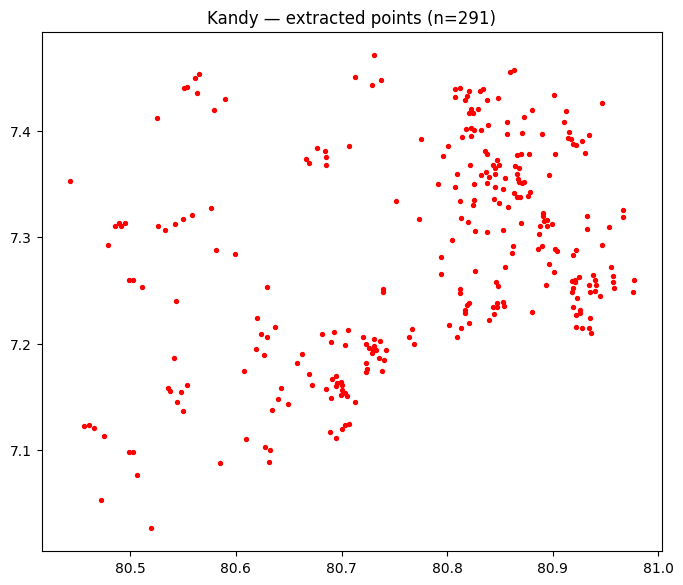

In [14]:
fig, ax = plt.subplots(figsize=(8,8))
gdf.plot(ax=ax, color="red", markersize=8)
ax.set_title(f"{MAP_NAME.capitalize()} — extracted points (n={len(gdf)})")
plt.show()


In [15]:
# ----- CHANGE PER MAP: read the total from the map's own DSD table -----
PRINTED_TOTAL = 380  # e.g. from "Total: 380" row in the DSD-wise table
# -------------------------------------------------------------------------

match_pct = len(gdf) / PRINTED_TOTAL * 100
print(f"Detected: {len(gdf)} / Printed total: {PRINTED_TOTAL} ({match_pct:.1f}% match)")



Detected: 291 / Printed total: 380 (76.6% match)


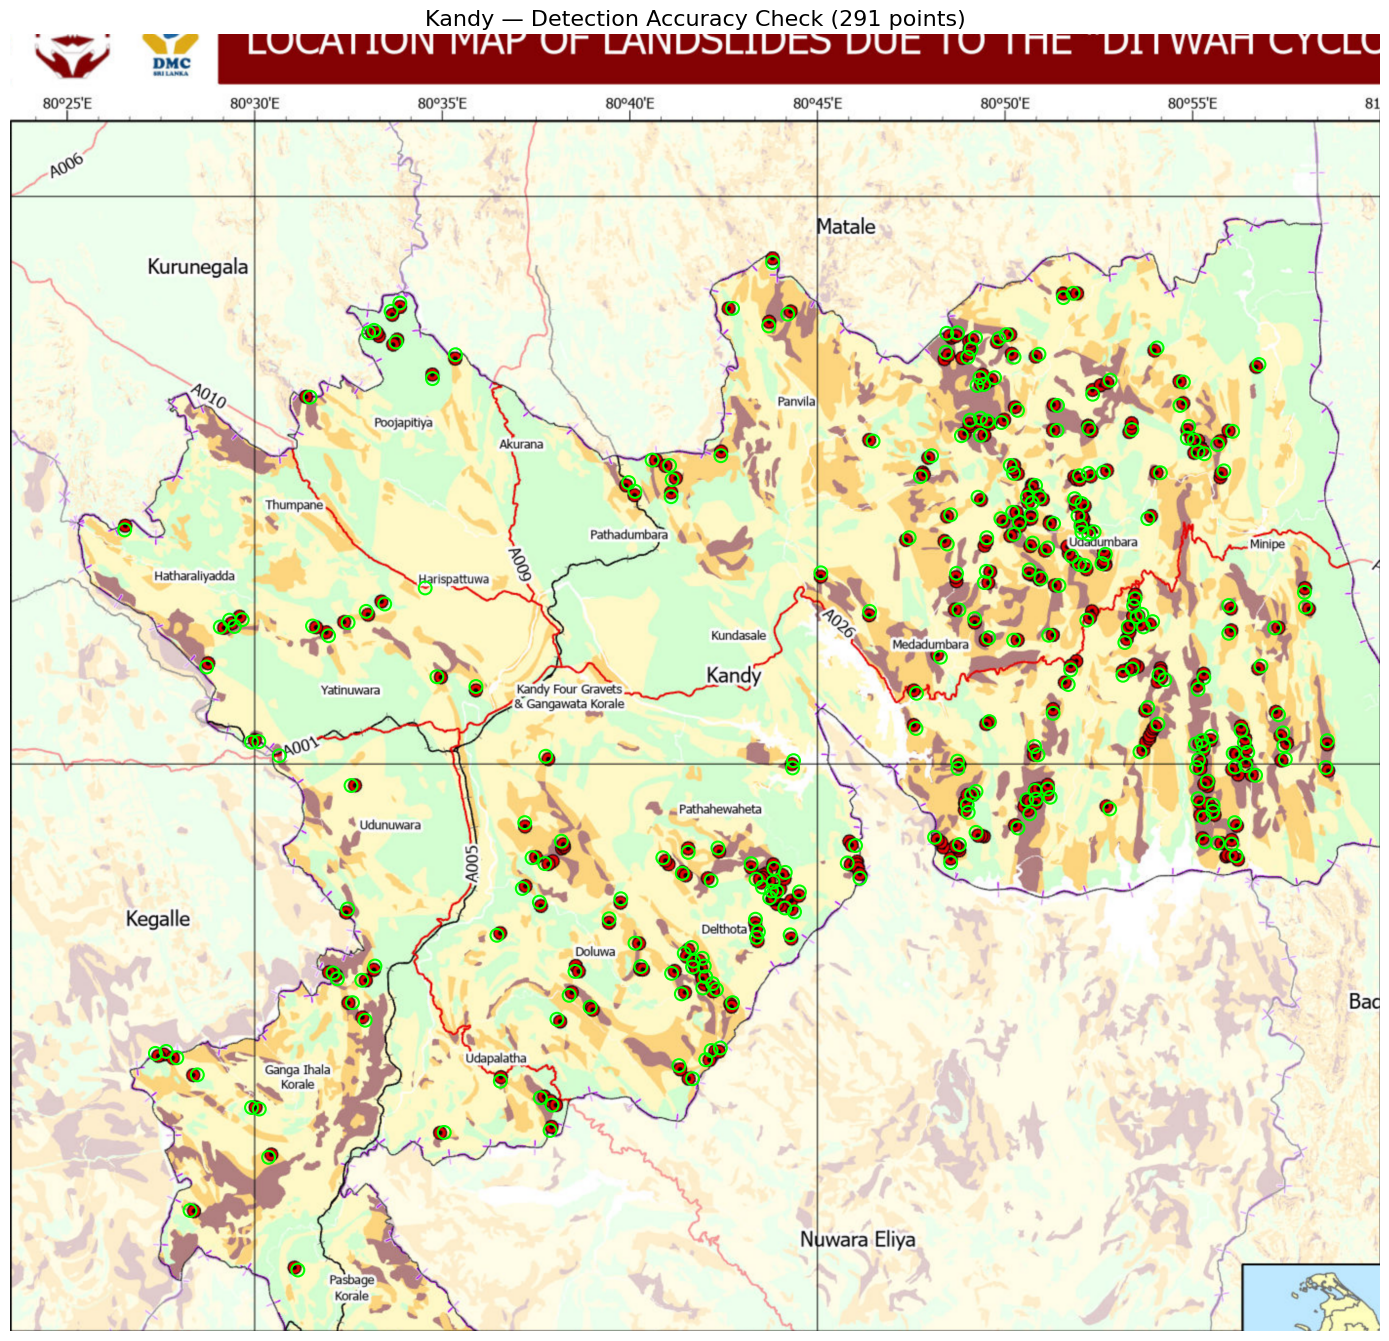

In [16]:
# Visual QA: overlay detected points on original NBRO map
# Circles are drawn in image-pixel (data) coordinates, sized to match
# the actual dot radius calibrated from SINGLE_DOT_AREA, so they scale
# correctly no matter how far you zoom in.

import numpy as np
import matplotlib.patches as mpatches
from matplotlib.collections import PatchCollection

fig, ax = plt.subplots(figsize=(14, 14))

ax.imshow(arr)

# radius (in px) of a single dot, from area = pi * r^2
dot_radius_px = np.sqrt(SINGLE_DOT_AREA / np.pi)

circles = [
    mpatches.Circle((x, y), radius=dot_radius_px * 1.3)  # slight margin so the ring is visible around the dot
    for x, y in points_px
]

ax.add_collection(
    PatchCollection(
        circles,
        facecolor="none",
        edgecolor="lime",
        linewidths=1.5
    )
)

ax.set_xlim(X_MIN, X_MAX)
ax.set_ylim(Y_MAX, Y_MIN)  # image Y axis runs downward

ax.set_title(
    f"{MAP_NAME.capitalize()} — Detection Accuracy Check ({len(points_px)} points)",
    fontsize=16
)

ax.axis("off")
plt.tight_layout()
plt.show()


In [17]:
import pandas as pd

rows = []
for i, (px, py) in enumerate(points_px, start=1):
    lon, lat = px_to_lonlat(px, py)
    rows.append({
        "id": i,
        "longitude": lon,
        "latitude": lat,
        "area_name": MAP_NAME.capitalize(),
        "pixel_x": px,
        "pixel_y": py
    })

df = pd.DataFrame(rows)
df.to_csv(DATA_PROCESSED /"kandy_landslide_points.csv", index=False)
print(f"Saved {len(df)} points to kandy_landslide_points.csv")

Saved 291 points to kandy_landslide_points.csv


### Part-02 Creating training table

In [18]:
from pathlib import Path

import geopandas as gpd
import pandas as pd
import numpy as np
import rasterio
import matplotlib.pyplot as plt

from shapely.geometry import Point

In [19]:
#  load your extracted Kandy landslide CSV

csv_path = DATA_PROCESSED / "kandy_landslide_points.csv"

assert csv_path.exists(), f"File not found: {csv_path}"

df = pd.read_csv(csv_path)

print(f"Rows loaded: {len(df)}")
print("Columns:", df.columns.tolist())

display(df.head())

Rows loaded: 291
Columns: ['id', 'longitude', 'latitude', 'area_name', 'pixel_x', 'pixel_y']


,id,longitude,latitude,area_name,pixel_x,pixel_y
0,1,80.730303,7.470790,Kandy,1733.0,568.0
1,2,80.863636,7.457259,Kandy,2349.0,631.0
2,3,80.859307,7.455326,Kandy,2329.0,640.0
3,4,80.564935,7.452964,Kandy,969.0,651.0
4,5,80.712554,7.450601,Kandy,1651.0,662.0


In [20]:
#  convert CSV coordinates to GeoDataFrame

kandy_pts = gpd.GeoDataFrame(
    df.copy(),
    geometry=gpd.points_from_xy(
        df["longitude"],
        df["latitude"]
    ),
    crs="EPSG:4326"
)

# Convert to the same UTM CRS used by the Sri Lanka rasters
kandy_utm = kandy_pts.to_crs("EPSG:32644")

# Landslide class
kandy_utm["label"] = 1

print(f"{len(kandy_utm)} landslide points loaded")
print("CRS:", kandy_utm.crs)

display(
    kandy_utm[
        ["id", "longitude", "latitude", "area_name", "label", "geometry"]
    ].head()
)

291 landslide points loaded
CRS: EPSG:32644


,id,longitude,latitude,area_name,label,geometry
0,1,80.730303,7.470790,Kandy,1,POINT (470242.44 825802.747)
1,2,80.863636,7.457259,Kandy,1,POINT (484953.62 824300.137)
2,3,80.859307,7.455326,Kandy,1,POINT (484475.889 824086.596)
3,4,80.564935,7.452964,Kandy,1,POINT (451994.012 823846.589)
4,5,80.712554,7.450601,Kandy,1,POINT (468282.608 823572.088)


In [21]:
# check that extracted points fall inside Kandy

aoi_path = DATA_PROCESSED / "aoi.gpkg"

aoi = gpd.read_file(
    aoi_path,
    layer="districts"
)

# Select Kandy
kandy_boundary = aoi[
    aoi["adm2_name"].astype(str).str.strip().str.lower() == "kandy"
].copy()

assert len(kandy_boundary) > 0, "Kandy district not found in AOI"

# IMPORTANT: convert boundary to same CRS as landslide points
kandy_boundary = kandy_boundary.to_crs("EPSG:32644")

# Merge Kandy polygon parts
try:
    kandy_poly = kandy_boundary.geometry.union_all()
except AttributeError:
    kandy_poly = kandy_boundary.unary_union

# Check points
within_kandy = kandy_utm.geometry.within(kandy_poly)

print(
    f"{within_kandy.sum()} / {len(kandy_utm)} "
    "points fall inside Kandy district"
)

# Keep only valid Kandy points
kandy_utm = (
    kandy_utm[within_kandy]
    .copy()
    .reset_index(drop=True)
)

print(f"Final landslide points: {len(kandy_utm)}")

289 / 291 points fall inside Kandy district
Final landslide points: 289


In [22]:
# generate matching non-landslide points

BUFFER_METERS = 500
RANDOM_SEED = 42

rng = np.random.default_rng(RANDOM_SEED)

# Create exclusion area around known landslides
try:
    buffer_union = kandy_utm.geometry.buffer(BUFFER_METERS).union_all()
except AttributeError:
    buffer_union = kandy_utm.geometry.buffer(BUFFER_METERS).unary_union

# Valid negative sampling area
valid_area = kandy_poly.difference(buffer_union)

assert not valid_area.is_empty, "No valid area available for negative sampling"

minx, miny, maxx, maxy = valid_area.bounds

n_needed = len(kandy_utm)

negatives = []
attempts = 0
max_attempts = max(10000, n_needed * 1000)

while len(negatives) < n_needed and attempts < max_attempts:

    pt = Point(
        rng.uniform(minx, maxx),
        rng.uniform(miny, maxy)
    )

    if valid_area.contains(pt):
        negatives.append(pt)

    attempts += 1


neg_gdf = gpd.GeoDataFrame(
    {
        "label": [0] * len(negatives)
    },
    geometry=negatives,
    crs="EPSG:32644"
)

print(f"Landslide points:     {len(kandy_utm)}")
print(f"Non-landslide points: {len(neg_gdf)}")
print(f"Sampling attempts:    {attempts}")

Landslide points:     289
Non-landslide points: 289
Sampling attempts:    683


In [23]:
#  combine positive and negative Kandy samples

positive_gdf = kandy_utm[
    ["geometry", "label"]
].copy()

combined = pd.concat(
    [
        positive_gdf,
        neg_gdf[["geometry", "label"]]
    ],
    ignore_index=True
)

combined = gpd.GeoDataFrame(
    combined,
    geometry="geometry",
    crs="EPSG:32644"
)

print("Total Kandy samples:", len(combined))

print("\nClass distribution:")
print(combined["label"].value_counts())

Total Kandy samples: 578

Class distribution:
label
1    289
0    289
Name: count, dtype: int64


In [24]:
# raster sampling helper

def sample_raster_at_points(raster_path, points_gdf, band=1):

    with rasterio.open(raster_path) as src:

        pts = points_gdf.to_crs(src.crs)

        coords = [
            (geom.x, geom.y)
            for geom in pts.geometry
        ]

        values = np.array(
            [v[band - 1] for v in src.sample(coords)],
            dtype="float64"
        )

        # Convert NoData to NaN
        if src.nodata is not None:
            values[values == src.nodata] = np.nan

        return values

In [25]:
#sample existing Sri Lanka terrain rasters

raster_map = {
    "slope": "slope.tif",
    "aspect": "aspect.tif",
    "twi": "twi.tif",
    "spi": "spi.tif",
    "dist_to_river": "dist_to_river.tif",
    "dist_to_road": "dist_to_road.tif",
    "elev": "dem_utm.tif",
    "plan_curv": "plan_curvature.tif",
    "profile_curv": "profile_curvature.tif",
}

available_features = []

for name, fname in raster_map.items():

    path = DATA_PROCESSED / fname

    if path.exists():

        combined[name] = sample_raster_at_points(
            path,
            combined
        )

        available_features.append(name)

        print(f"{name}: sampled")

    else:
        print(f"{name}: MISSING — {fname}")

slope: sampled
aspect: sampled
twi: sampled
spi: sampled
dist_to_river: sampled
dist_to_road: sampled
elev: sampled
plan_curv: sampled
profile_curv: sampled


In [26]:
# metadata and cleaning

combined["country"] = "Sri Lanka"
combined["source_dataset"] = "NBRO_Kandy_MapExtraction"
combined["district"] = "Kandy"

# Replace infinite terrain values
combined[available_features] = combined[
    available_features
].replace(
    [np.inf, -np.inf],
    np.nan
)

print("Missing raster values:")
print(combined[available_features].isna().sum())

combined_clean = combined.dropna(
    subset=available_features
).copy()

print(
    f"\nClean Kandy rows: "
    f"{len(combined_clean)} / {len(combined)}"
)

Missing raster values:
slope            1
aspect           1
twi              1
spi              1
dist_to_river    1
dist_to_road     1
elev             1
plan_curv        1
profile_curv     1
dtype: int64

Clean Kandy rows: 577 / 578


In [27]:
# load existing Sri Lanka COOLR labels

old_labels_path = DATA_PROCESSED / "labels.parquet"

if old_labels_path.exists():

    old_labels = gpd.read_parquet(old_labels_path)

    old_labels = old_labels.to_crs("EPSG:32644")

    print(
        f"Existing COOLR samples: {len(old_labels)}"
    )

else:
    old_labels = None
    print("labels.parquet not found")

Existing COOLR samples: 78


In [28]:
# prepare and re-sample COOLR points

if old_labels is not None:

    old_labels["source_dataset"] = "COOLR"
    old_labels["country"] = "Sri Lanka"

    if "adm2_name" in old_labels.columns:
        old_labels["district"] = old_labels["adm2_name"]
    else:
        old_labels["district"] = "unknown"


    # Sample SAME current rasters for COOLR points
    for name, fname in raster_map.items():

        path = DATA_PROCESSED / fname

        if path.exists():

            old_labels[name] = sample_raster_at_points(
                path,
                old_labels
            )

            print(f"COOLR {name}: sampled")


    old_labels[available_features] = old_labels[
        available_features
    ].replace(
        [np.inf, -np.inf],
        np.nan
    )


    old_labels_clean = old_labels.dropna(
        subset=available_features
    ).copy()

    print(
        f"Clean COOLR rows: "
        f"{len(old_labels_clean)}"
    )

COOLR slope: sampled
COOLR aspect: sampled
COOLR twi: sampled
COOLR spi: sampled
COOLR dist_to_river: sampled
COOLR dist_to_road: sampled
COOLR elev: sampled
COOLR plan_curv: sampled
COOLR profile_curv: sampled
Clean COOLR rows: 78


In [29]:
#  merge old COOLR + new Kandy dataset

shared_cols = [
    "geometry",
    "label",
    "country",
    "source_dataset",
    "district",
] + available_features


if old_labels is not None:

    combined_all = pd.concat(
        [
            old_labels_clean[shared_cols],
            combined_clean[shared_cols]
        ],
        ignore_index=True
    )

else:

    combined_all = combined_clean[
        shared_cols
    ].copy()


combined_all = gpd.GeoDataFrame(
    combined_all,
    geometry="geometry",
    crs="EPSG:32644"
)


print(
    f"Total Sri Lanka samples: "
    f"{len(combined_all)}"
)

display(
    combined_all
    .groupby(["source_dataset", "label"])
    .size()
    .unstack(fill_value=0)
)

Total Sri Lanka samples: 655


label,0,1
source_dataset,,
COOLR,39,39
NBRO_Kandy_MapExtraction,288,289


In [30]:
# save final training table

parquet_path = (
    DATA_PROCESSED /
    "training_table_sri_lanka_v2.parquet"
)

combined_all.to_parquet(
    parquet_path,
    index=False
)

print("Saved:", parquet_path)

Saved: ..\data\processed\training_table_sri_lanka_v2.parquet


In [31]:
# also save as CSV

csv_output = combined_all.copy()

# UTM coordinates
csv_output["x"] = csv_output.geometry.x
csv_output["y"] = csv_output.geometry.y

# Longitude / latitude
wgs84 = csv_output.to_crs("EPSG:4326")

csv_output["longitude"] = wgs84.geometry.x
csv_output["latitude"] = wgs84.geometry.y

# Remove geometry object
csv_output = pd.DataFrame(
    csv_output.drop(columns="geometry")
)

csv_out_path = (
    DATA_PROCESSED /
    "training_table_sri_lanka_v2.csv"
)

csv_output.to_csv(
    csv_out_path,
    index=False
)

print("Saved:", csv_out_path)
print("Shape:", csv_output.shape)

display(csv_output.head())

Saved: ..\data\processed\training_table_sri_lanka_v2.csv
Shape: (655, 17)


,label,country,source_dataset,district,slope,aspect,twi,spi,dist_to_river,dist_to_road,elev,plan_curv,profile_curv,x,y,longitude,latitude
0,1,Sri Lanka,COOLR,Badulla,8.794240,9.317299,1.866234,0.154705,253.139816,30.697712,1768.088623,0.025243,-0.000171,482851.481170,753809.104834,80.8448,6.8196
1,1,Sri Lanka,COOLR,Badulla,6.548500,217.219971,3.774061,0.573966,0.000000,61.395424,750.929077,0.003153,-0.002880,502684.207822,768940.164973,81.0243,6.9565
2,1,Sri Lanka,COOLR,Nuwara Eliya,14.880496,267.809479,3.404773,2.125720,43.413120,86.826241,1011.710144,0.002502,-0.002175,454860.312391,776090.023077,80.5913,7.0210
3,1,Sri Lanka,COOLR,Kalutara,6.143241,205.529968,2.922179,0.215265,43.413120,92.093132,25.290115,-0.003375,-0.000577,406718.316685,721439.442074,80.1563,6.5261
4,1,Sri Lanka,COOLR,Badulla,28.810682,161.704666,4.235428,20.899904,0.000000,110.682175,1048.303345,-0.003051,-0.001493,502309.571111,747560.571913,81.0209,6.7631


In [32]:
import pandas as pd

# Load existing CSV
df = pd.read_csv(
    DATA_PROCESSED / "training_table_sri_lanka_v2.csv"
)

print("Before removing COOLR:", len(df))

# Remove ALL COOLR rows
df_clean = df[
    df["source_dataset"].astype(str).str.strip().str.upper() != "COOLR"
].copy()

df_clean.reset_index(drop=True, inplace=True)

print("After removing COOLR:", len(df_clean))

# Check remaining datasets
print("\nRemaining source datasets:")
print(df_clean["source_dataset"].value_counts())

# Save
output_path = (
    DATA_PROCESSED /
    "training_table_kandy_clean.csv"
)

df_clean.to_csv(
    output_path,
    index=False
)

print("\nSaved:", output_path)

Before removing COOLR: 655
After removing COOLR: 577

Remaining source datasets:
source_dataset
NBRO_Kandy_MapExtraction    577
Name: count, dtype: int64

Saved: ..\data\processed\training_table_kandy_clean.csv
